<a href="https://colab.research.google.com/github/joebathelt/UvA_MLM_fMRI/blob/main/MLM_fMRI_Week5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 5: Group-level Analysis and Multiple Comparison Correction

In this notebook, you will learn how to combine fMRI results across participants, so that we can draw conclusions that go beyond the people we scanned: for example, which brain regions are generally involved in processing faces.

Last week, you fitted a GLM that related the experimental conditions to brain activity in one run of one participant. This first-level analysis is the building block of every task fMRI study, and it is repeated for every run of every participant. The results are then combined in a group-level analysis. The group-level model is usually much simpler than the first-level model. Typically, we ask which areas respond consistently across participants, or whether the response differs between groups (for example, patients and controls) or changes with a characteristic such as age.

We start by learning how to **visualise** statistical maps with nilearn, using slices, glass brains, the cortical surface and atlas regions. In the second part, we run a **group-level analysis** of real data: the faces > others contrast of 12 participants who completed a functional localiser task. You will build a group-level design matrix, fit a **random-effects** model, and then extend it to a **mixed-effects** analysis that weights each participant by the precision of their estimates.

A whole-brain analysis involves more than 200,000 statistical tests, one for each voxel. At the usual threshold of p < 0.05, about 10,000 voxels would look "significant" even if no region truly responded. In the third part, you will learn how to **correct for multiple comparisons**: you will compare Bonferroni correction, the false discovery rate, random field theory and cluster-extent thresholding on simulated data, and then apply them to our group-level map. In the fourth part, you will learn about **non-parametric** permutation tests, which build the null distribution from the data themselves. Finally, you will see how a **region-of-interest analysis** increases sensitivity by reducing the number of tests to a region chosen in advance.

**Estimated time**: 4-5 hours

**Assessment**: This exercise is not graded. However, you will need to complete a multiple-choice quiz in the next session that tests your understanding of the topics covered in this notebook. This includes your understanding of the concepts covered in this notebook as well as the code implementation. Please refer to the example quiz on Canvas and read the learning objectives below for further guidance.

**Credits**:
Written by Joe Bathelt in 2026, based on original materials from Lukas Snoek & H. Steven Scholte, a blog post by [Matthew Brett](https://matthew-brett.github.io/teaching/random_fields.html), and examples from https://nilearn.github.io/. The data are from the NI-edu dataset ([ds003965](https://openneuro.org/datasets/ds003965/versions/1.0.0)) on OpenNeuro.

**Learning Objectives**:
- The student can create **appropriate visualisations** of task fMRI statistical analyses
- The student can **implement appropriate multi-level models** to combine data across runs and participants
- The student can implement **region-of-interest** and **whole-brain analyses**
- The student can apply **Bonferroni and False Discovery Rate** correction for multiple comparisons

**Important**: We are using Google Colab for this course. If you are using a different environment, please make sure you have the required packages installed. Some of the required packages are not part of the default Python installation on Colab. We include a cell at the beginning of the notebook to install those packages. When you restart the notebook, you will need to run that cell again to make sure the packages are installed. If you get an error message that a package is not found, please run the installation cell again.

In [ ]:
# Installing required packages
!pip install nilearn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 978.8 kB/s eta 0:00:00 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.5/11.5 MB 45.2 MB/s eta 0:00:0000:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 50.4 MB/s eta 0:00:0000:010:01m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 6.0 MB/s eta 0:00:00
  Attempting uninstall: requests
    Found existing installation: requests 2.32.4
    Uninstalling requests-2.32.4:
      Successfully uninstalled requests-2.32.4
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.3
    Uninstalling pandas-2.2.3:
      Successfully uninstalled pandas-2.2.3
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2

In [ ]:
# Loading required packages
import matplotlib.pyplot as plt
from nilearn import datasets, image, surface, plotting
import numpy as np
from IPython.display import display
import ipywidgets as widgets

# Part I: Visualising statistical images

Visualisation is a key step in any neuroimaging workflow — after all, it’s called *imaging* for a reason.  
By looking at your statistical maps, you can quickly detect potential errors in the analysis and clearly communicate your findings to others.  

In this section, you will learn how to use **Nilearn** to visualise statistical images effectively.

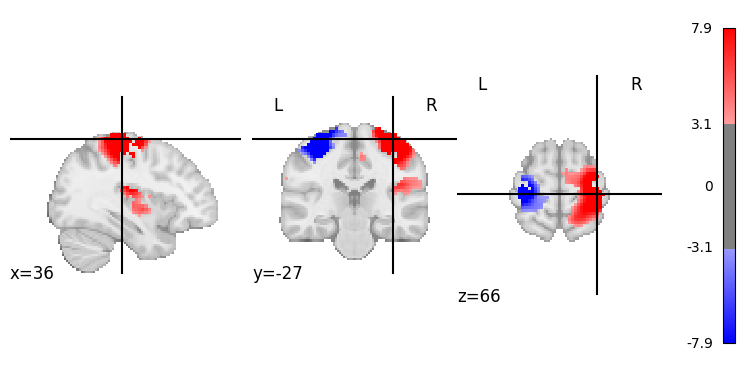

In [ ]:
# Loading an example functional image
stat_img = datasets.load_sample_motor_activation_image()

# Visualizing t-map image on EPI template with manual threshold
plotting.plot_stat_map(
    stat_img,
    threshold=3.1, # Statistic threshold
    cut_coords=[36, -27, 66], # MNI coordinates of the slice
    cmap='bwr' # Colour map. Alternatives: 'bwr', 'hot_black_bone'
)

Try adjusting the parameters in the code cell below to see how they affect the visualisation.  
Pay special attention to the **cut coordinates** — how do different settings change the way you interpret the data?

In [ ]:
# Function to plot t-map with adjustable parameters
def interactive_stat_map(threshold, x_coord, y_coord, z_coord, cmap):
    plotting.plot_stat_map(
        stat_img,
        threshold=threshold,
        cut_coords=[x_coord, y_coord, z_coord],
        cmap=cmap
    )

# Interactive widgets
threshold_slider = widgets.FloatSlider(value=3.1, min=0, max=10, step=0.1, description="Threshold")
x_coord_slider = widgets.IntSlider(value=36, min=-50, max=50, step=1, description="X Coord")
y_coord_slider = widgets.IntSlider(value=-27, min=-50, max=50, step=1, description="Y Coord")
z_coord_slider = widgets.IntSlider(value=66, min=-50, max=50, step=1, description="Z Coord")
cmap_dropdown = widgets.Dropdown(
    options=['bwr', 'hot_black_bone', 'cyan_orange'],
    value='bwr',
    description="Colormap"
)

# Display interactive plot
widgets.interactive(interactive_stat_map,
                    threshold=threshold_slider,
                    x_coord=x_coord_slider,
                    y_coord=y_coord_slider,
                    z_coord=z_coord_slider,
                    cmap=cmap_dropdown)

interactive(children=(FloatSlider(value=3.1, description='Threshold', max=10.0), IntSlider(value=36, descripti…

The figure displays the thresholded statistical map overlaid on the MNI anatomical template.  
The cross marks the chosen **cut coordinates** (also listed below the figure), and the colour bar on the right shows the corresponding **t-values** from the statistical map.

<div class='alert alert-warning'>
<b>ToDo</b>:  
Experiment with the visualisation settings of the statistical image:  

- **Threshold**: Increase or decrease the threshold.  
- **Colormap**: Switch between different colour maps.  
- **Cut coordinates**: Move the cuts along the x, y, or z-axis.  

👉 What changes do you notice, and how do they affect your interpretation of the results?  
</div>

<details>
<summary><b>Possible observations</b></summary>

- Increasing the **threshold** removes weaker activations, making only the strongest clusters visible.  
- Decreasing the **threshold** can make more clusters appear, but also increases the risk of including noise.  
- Changing the **colormap** does not alter the data, but can make clusters more or less easy to see.  
- Adjusting the **cut coordinates** helps you focus on different regions of the brain and may reveal activations that are not visible in the default slices.  

</details>

The figure above shows activation at a specific location.  
However, we often want to visualise activation across the **entire brain**.  

For this, we can use a **glass brain plot** — a transparent brain outline that displays all activations in a single view.  
The figure below shows the same statistical map as above, but rendered as a glass brain.

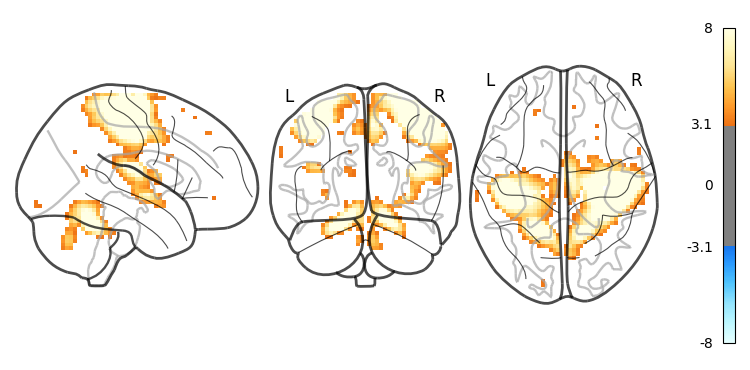

In [ ]:
plotting.plot_glass_brain(
    stat_img,
    threshold=3.1,
    cmap='cyan_orange',
    colorbar=True,
    symmetric_cbar=True,
    vmax=8
    )

Try adjusting the parameters in the cell below to explore how they affect the visualisation.  
Pay attention to how changes in the **colormap** or **threshold** influence your interpretation of the data.

In [ ]:
# Function to plot glass brain with adjustable parameters
def interactive_glass_brain(threshold, cmap, symmetric_cbar):
    plotting.plot_glass_brain(
        stat_img,
        threshold=threshold,
        cmap=cmap,
        colorbar=True,
        vmax=8,
        symmetric_cbar=symmetric_cbar,
    )

# Interactive widgets
threshold_slider = widgets.FloatSlider(value=3.1, min=0, max=5, step=0.1, description="Threshold")
cmap_dropdown = widgets.Dropdown(
    options=['cyan_orange', 'bwr', 'hot_black_bone'],
    value='cyan_orange',
    description="Colormap"
)
symmetric_cbar_toggle = widgets.Checkbox(value=True, description="Symmetric Colorbar")

# Display interactive plot
widgets.interactive(interactive_glass_brain,
                    threshold=threshold_slider,
                    cmap=cmap_dropdown,
                    symmetric_cbar=symmetric_cbar_toggle)

interactive(children=(FloatSlider(value=3.1, description='Threshold', max=5.0), Dropdown(description='Colormap…

<div class='alert alert-info'>
<b>Reflection:</b>
    What are the advantages and disadvantages of the <b>glass brain plot </b> compared to the <b>anatomical plot</b>?  
When might you choose one over the other?  
</div>

<details>
<summary><b>Solution</b> (click to expand)</summary>

- **Glass brain plot**  
  - Advantages: gives a quick overview of activations across the whole brain; easy to spot overall patterns.  
  - Disadvantages: less anatomical detail, precise localisation can be difficult.  

- **Anatomical plot**  
  - Advantages: shows activation in relation to brain anatomy; allows precise localisation of effects.  
  - Disadvantages: only displays selected slices or regions, so some activations may be missed.  

In practice:  
- Use a **glass brain** for a fast, whole-brain overview (e.g. in figures summarising results).  
- Use an **anatomical plot** when you need detailed localisation or want to highlight specific regions.  

</details>

Sometimes, instead of visualising activation in the **volume**, we may want to display it directly on the **cortical surface**.  
This is especially useful when highlighting activation patterns along the cortex.  

The figure below shows the same statistical map as before, but now projected onto the cortical surface.  

---

**Side note:**  
It is also possible to perform statistical analysis on the cortical surface rather than in the volume.  
- Supporters argue that surface-based analysis offers **better anatomical specificity**, since it respects the complex folds of the cortex that can be obscured in volumetric representations.  
- Critics note that fMRI data is inherently **voxel-based**, and therefore more naturally analysed in the volume.  
- Surface-based analysis is also more **computationally demanding**.  

The debate remains unresolved, but importantly: the **statistical principles** you are learning in this course apply equally to both surface- and volume-based approaches.

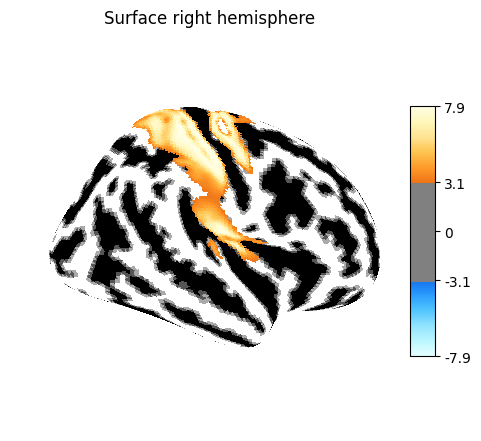

In [ ]:
# Loading the surface
fsaverage = datasets.fetch_surf_fsaverage()
curv_right = surface.load_surf_data(fsaverage.curv_right)
curv_right_sign = np.sign(curv_right)

# Mapping the statistical map from volume to the surface
texture = surface.vol_to_surf(stat_img, fsaverage.pial_right)

# Plotting the statistical map on the surface
fig = plotting.plot_surf_stat_map(
    fsaverage.infl_right,
    texture,
    hemi='right',
    title='Surface right hemisphere',
    colorbar=True,
    threshold=3.1,
    cmap='cyan_orange',
    bg_map=curv_right_sign,
)
fig.show()

You can try out different surface in the code cell below. How does your impression of the location of the activation change when you switch between the inflated and white matter surface?

In [ ]:
# Load fsaverage surface and sample statistical image
fsaverage = datasets.fetch_surf_fsaverage()
stat_img = datasets.load_sample_motor_activation_image()

# Load surface curvature data and calculate sign
curv_right = surface.load_surf_data(fsaverage.curv_right)
curv_right_sign = np.sign(curv_right)

# Map the statistical map from volume to the surface
texture = surface.vol_to_surf(stat_img, fsaverage.pial_right)

# Function to plot surface map with adjustable parameters
def interactive_surf_stat_map(threshold, cmap, surface_type):
    # Select surface based on user input
    surf_mesh = getattr(fsaverage, surface_type)

    plotting.plot_surf_stat_map(
        surf_mesh,
        texture,
        hemi='right',
        title=f'Surface right hemisphere ({surface_type})',
        colorbar=True,
        threshold=threshold,
        cmap=cmap,
        bg_map=curv_right_sign,
    )

# Interactive widgets
threshold_slider = widgets.FloatSlider(value=3.1, min=0, max=10, step=0.1, description="Threshold")
cmap_dropdown = widgets.Dropdown(
    options=['cyan_orange', 'bwr', 'hot_black_bone'],
    value='cyan_orange',
    description="Colormap"
)
surface_dropdown = widgets.Dropdown(
    options=['infl_right', 'white_right', 'sphere_right'],
    value='infl_right',
    description="Surface Type"
)

# Display interactive plot
widgets.interactive(interactive_surf_stat_map,
                    threshold=threshold_slider,
                    cmap=cmap_dropdown,
                    surface_type=surface_dropdown)

interactive(children=(FloatSlider(value=3.1, description='Threshold', max=10.0), Dropdown(description='Colorma…

Sometimes it is useful to display the location of specific **anatomical regions** on the brain.  
For example, you might want to:  
- show the outline of a **region of interest (ROI)**, or  
- provide additional anatomical context to help interpret the results of a whole-brain analysis.  

In the example below, we load an anatomical atlas and plot the outline of a selected region.  
Here we highlight the **motor cortex**, since the statistical map comes from a motor task.

In [ ]:
# Function to plot the brain with different atlas label overlays
def interactive_atlas_brain(region_label):

    # Loading the Harvard-Oxford cortical atlas
    dataset_ho = datasets.fetch_atlas_harvard_oxford("cort-maxprob-thr25-2mm")

    # Specify the region of interest by its label
    region_index = dataset_ho.labels.index(region_label)

    # Load the atlas image
    atlas_img = image.load_img(dataset_ho.filename)

    # Create a binary mask for the region of interest
    region_mask_data = np.zeros(atlas_img.shape, dtype=np.int32)
    region_mask_data[atlas_img.get_fdata() == region_index] = 1

    # Create a Nifti image for the region mask
    region_mask_img = image.new_img_like(atlas_img, region_mask_data)

    # Display the region mask
    plotting.plot_roi(region_mask_img,
                    view_type='contours',
                    title=f'Region: {region_label}')
    plotting.show()

# Loading the Harvard-Oxford cortical atlas
dataset_ho = datasets.fetch_atlas_harvard_oxford("cort-maxprob-thr25-2mm")

# Interactive widgets
region_dropdown = widgets.Dropdown(
    options=dataset_ho.labels,
    value='Precentral Gyrus',
    description="Atlas Label"
)

# Display interactive plot
widgets.interactive(interactive_atlas_brain,
                    dataset_ho=dataset_ho,
                    region_label=region_dropdown)

[fetch_atlas_harvard_oxford] Added README.md to /root/nilearn_data

[fetch_atlas_harvard_oxford] Dataset created in /root/nilearn_data/fsl

[fetch_atlas_harvard_oxford] Downloading data from https://www.nitrc.org/frs/download.php/9902/HarvardOxford.tgz ...

[fetch_atlas_harvard_oxford] Downloaded 1015808 of 25716861 bytes (3.9%%, 00 HR 00 MIN 27 SEC remaining)

[fetch_atlas_harvard_oxford] Downloaded 15556608 of 25716861 bytes (60.5%%, 00 HR 00 MIN 01 SEC remaining)

[fetch_atlas_harvard_oxford] Downloaded 25468928 of 25716861 bytes (99.0%%, 00 HR 00 MIN 00 SEC remaining)

[fetch_atlas_harvard_oxford]  ...done. (4 seconds, 0 min)

[fetch_atlas_harvard_oxford] Extracting data from /root/nilearn_data/fsl/6932472d2796019d1a5432f4c5215f42/HarvardOxford.tgz...

[fetch_atlas_harvard_oxford] .. done.

interactive(children=(Dropdown(description='Atlas Label', index=7, options=('Background', 'Frontal Pole', 'Ins…

We can combine the visualisation of the ROI with the statistical map:

[fetch_atlas_harvard_oxford] Dataset directory found: /root/nilearn_data/fsl

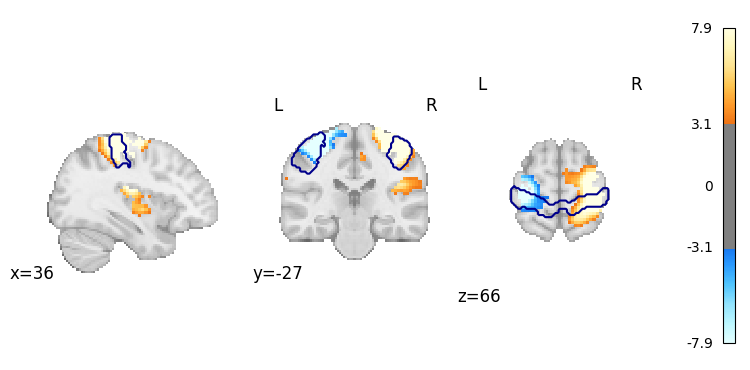

In [ ]:
# Loading the Harvard-Oxford cortical atlas
dataset_ho = datasets.fetch_atlas_harvard_oxford("cort-maxprob-thr25-2mm")

# Specify the region of interest by its label
region_index = dataset_ho.labels.index('Postcentral Gyrus')

# Load the atlas image
atlas_img = image.load_img(dataset_ho.filename)

# Create a binary mask for the region of interest
region_mask_data = np.zeros(atlas_img.shape, dtype=np.int32)
region_mask_data[atlas_img.get_fdata() == region_index] = 1

# Create a Nifti image for the region mask
region_mask_img = image.new_img_like(atlas_img, region_mask_data)

display = plotting.plot_stat_map(
    stat_img,
    threshold=3.1, # Statistic threshold
    cut_coords=[36, -27, 66], # MNI coordinates of the slice
    cmap='cyan_orange', # Colour map. Alternatives: 'bwr', 'hot_black_bone'
    draw_cross=False
)
display.add_contours(region_mask_img, levels=[0.5], colors='darkblue')
plotting.show()

Once you are happy with a plot, you can save it to a file using **`plt.savefig()`**.  
- The **filename extension** determines the file format (e.g. `my_figure.png` for PNG, `my_figure.pdf` for PDF).  
- Important: call `plt.savefig()` **before** `plt.show()`.  
  If you save after showing, the figure will be cleared and the saved file will be empty.

<div class='alert alert-warning'>
<b>ToDo</b>: Create a visualisation of the statistical map shown below.  

**Instructions:**  
- Use a **glass brain plot**  
- Apply a **threshold of 3.1**  
- Use the **'bwr' colormap**  
- Set the **title** to: *"Reading > Checkerboard"*  
- Assign the resulting plot to the variable **`fig`**  

    
💡 **Note**: This will be graded manually (no feedback cell).
</div>

In [ ]:
from nilearn import plotting, image
import matplotlib.pyplot as plt

# Load the language meta-analysis statistical image
stat_img = datasets.fetch_localizer_contrasts(
     ['sentence reading vs checkerboard'],
     n_subjects=1,
     get_tmaps=True
)['tmaps'][0]

### YOUR CODE HERE ###

[fetch_localizer_contrasts] Dataset created in /root/nilearn_data/brainomics_localizer

[fetch_localizer_contrasts] Downloading data from https://osf.io/hwbm2/download ...

[fetch_localizer_contrasts] Downloaded 212992 of 1508563 bytes (14.1%%, 00 HR 00 MIN 06 SEC remaining)

[fetch_localizer_contrasts]  ...done. (6 seconds, 0 min)

[fetch_localizer_contrasts] Downloading data from https://osf.io/download/5d27cd441c5b4a001aa08008/ ...

...

[fetch_localizer_contrasts]  ...done. (4 seconds, 0 min)

[fetch_localizer_contrasts] Downloading data from https://osf.io/download/5d27037f45253a001c3d4563/ ...

[fetch_localizer_contrasts]  ...done. (2 seconds, 0 min)

[fetch_localizer_contrasts] Downloading data from https://osf.io/download/5d7b8948fcbf44001c44e695/ ...

[fetch_localizer_contrasts]  ...done. (2 seconds, 0 min)

In this section, you learned how to plot statistical images using **Nilearn**. These skills are essential for the upcoming exercises. Remember: **visualising your data is one of the best ways to catch errors and build intuition** about your analysis.

---
## Part II: Group-Level Analysis
---

In this week's lecture, we discussed **multi-level models** and the **summary statistics approach**. Outside of fMRI, data from multiple runs or participants are often analysed in one large model that includes all the data at once. fMRI datasets are too large for this to be practical. Instead, we use the summary statistics approach. First, we fit a GLM to each run or participant separately: the **first-level analysis**. Then, we take the contrast estimates from these models and combine them in a new GLM: the **group-level analysis** (also called the second-level analysis).

In this part, you will apply this approach to data from multiple participants and test whether an effect is consistent across the group. We will use a **parametric** test here. In Part III, you will learn how to correct for multiple comparisons, and in Part IV about non-parametric alternatives.

![](https://docs.google.com/drawings/d/e/2PACX-1vQxCH3WU3nTqFlHUZb49rf9zioivGQ-flVfRpwmXQx7OF5Wm_1T6gFMYQqpqt-NPITNHUaRoVYEREgT/pub?w=965&h=745)

#### Random Effects

We use a **random-effects analysis**, the standard approach for group-level fMRI analysis (it is the default in SPM, for example). A random-effects analysis treats our participants as a random sample from a larger population. This is what allows us to generalise the results beyond the people we scanned.

#### The Data

We return to the NI-edu dataset ([ds003965](https://openneuro.org/datasets/ds003965/versions/1.0.0)) from last week, but now use the `flocBLOCKED` task. This is a functional localiser: participants viewed blocks of pictures of faces, bodies, places, characters and objects. We have already run the first-level analyses in FSL for you, for 12 participants (sub-02 to sub-13), with the contrast **faces > others**: the response to faces compared with the average response to the other four categories. Each participant's runs have already been combined, and all maps have been normalised to MNI space. This means that we can start directly at the group level, with one contrast map per participant.

All 12 maps are stored in a single 4D image, in which the fourth dimension is the participant rather than time. The code below downloads this image together with a brain mask, and splits it into a list of 12 3D images.

In [ ]:
import os
import urllib.request

def download_openneuro(dataset, version, path, outfile=None):
    """Download a file from an OpenNeuro dataset if not already present."""
    url = (f"https://openneuro.org/crn/datasets/{dataset}/snapshots/{version}/files/"
           + path.replace("/", ":"))
    if outfile is None:
        outfile = os.path.basename(path)
    if not os.path.exists(outfile):
        print(f"Downloading {outfile}...")
        urllib.request.urlretrieve(url, outfile)
    else:
        print(f"{outfile} already exists, skipping download.")
    return outfile

# Folder with the input of the group-level analysis that we ran in FSL
group_dir = ("derivatives/fsl/grouplevel_task-flocBLOCKED/"
             "contrast-faceGTother_method-FLAME1_thresh-uncorr05.gfeat/cope1.feat")

# 4D image with one faces > others map per participant, and the brain mask
cope_file = download_openneuro("ds003965", "1.0.0", f"{group_dir}/filtered_func_data.nii.gz",
                               "faces_gt_others_maps.nii.gz")
mask_file = download_openneuro("ds003965", "1.0.0", f"{group_dir}/mask.nii.gz",
                               "group_mask.nii.gz")

# Splitting the 4D image into a list of 3D images: one per participant
subject_maps = list(image.iter_img(cope_file))
subject_labels = [f'sub-{i:02d}' for i in range(2, 14)]
print(f'{len(subject_maps)} participant maps with shape {subject_maps[0].shape}')

12 participant maps with shape (91, 109, 91)


Before we run any statistics, it is a good idea to look at the data. The code below shows the same axial slice through the ventral temporal cortex for each participant. Red means a stronger response to faces than to the other categories, blue the opposite. All maps use the same colour scale, and none of them is thresholded.

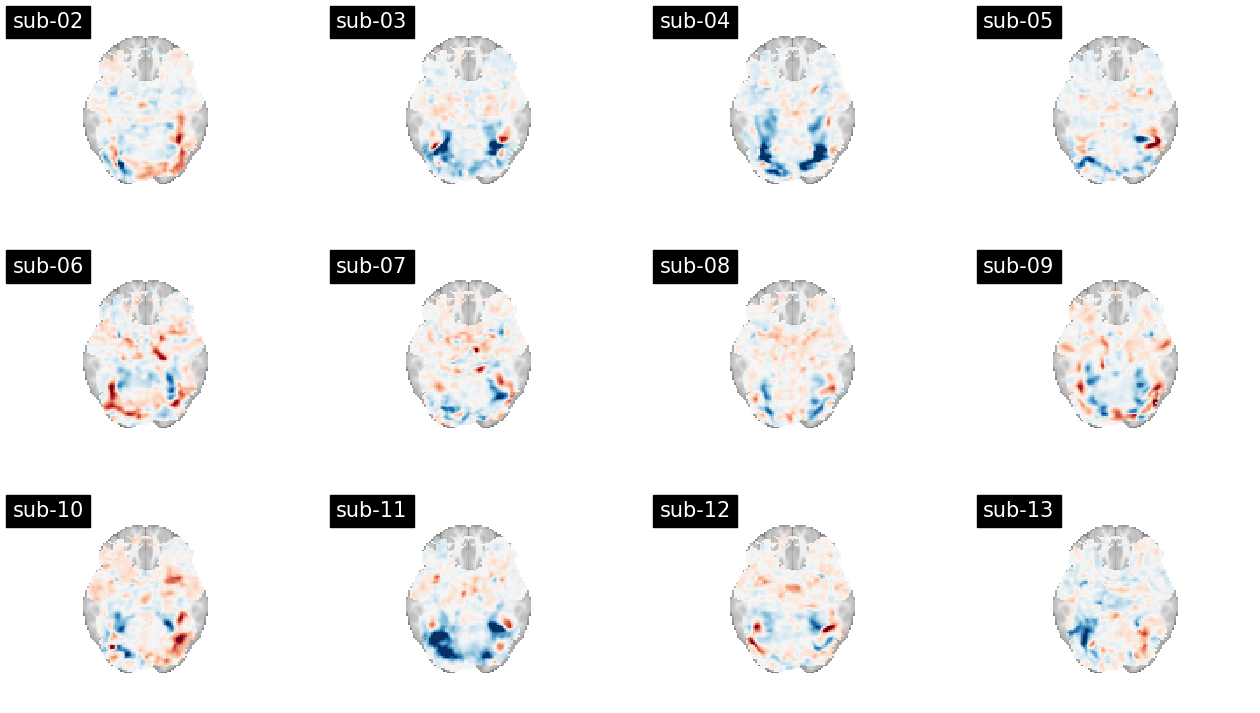

In [ ]:
# Using the same colour scale for all participants
mask = image.load_img(mask_file).get_fdata() > 0
vmax = np.percentile(np.abs(image.load_img(cope_file).get_fdata()[mask]), 99.9)

fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(16, 9))
for ax, subject_map, label in zip(axes.flat, subject_maps, subject_labels):
    plotting.plot_stat_map(
        subject_map,
        display_mode='z',
        cut_coords=[-18],   # axial slice through the fusiform gyrus
        vmax=vmax,
        colorbar=False,
        annotate=False,
        title=label,
        axes=ax,
    )
plt.show()

In many participants, you can see red spots on the lateral side of the fusiform gyrus, roughly where the **fusiform face area** (FFA) is expected, and blue areas closer to the midline, which respond more strongly to places and objects. However, the maps also differ a lot between participants: the size, strength and exact location of the face-selective spots vary, and in some participants they are hard to find at all. The group-level analysis asks which of these effects are consistent enough across participants to generalise to the population.

#### The Group-Level Design Matrix

Just like the first-level GLM, the group-level GLM needs a **design matrix**. At the group level, each row is a participant rather than a time point, and the data for each voxel are the 12 contrast estimates from the first-level analyses.

Our question is simple: is the faces > others effect on average larger than zero? For this, the design matrix needs only one column, with a 1 for every participant. The $\beta$ estimate for this column is the mean effect across participants, and testing it against zero is the same as a **one-sample t-test** in every voxel. More columns could be added to answer other questions, for example a column with each participant's age, or columns that code for two groups.

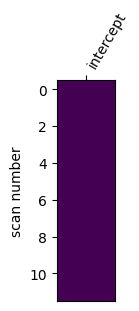

In [ ]:
import pandas as pd
from nilearn.plotting import plot_design_matrix

# Group-level design matrix: one row per participant and a single column of ones
design_matrix = pd.DataFrame({'intercept': np.ones(len(subject_maps))}, index=subject_labels)

plot_design_matrix(design_matrix)
plt.show()

We now fit the group-level GLM with nilearn's `SecondLevelModel`. It works like the `FirstLevelModel` you used last week: we fit the model to the data and the design matrix, and then compute a contrast. Here, the contrast is simply the `intercept` column: the mean effect across participants.

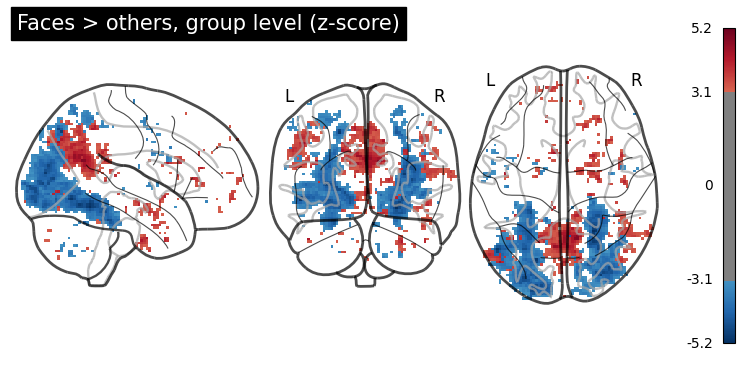

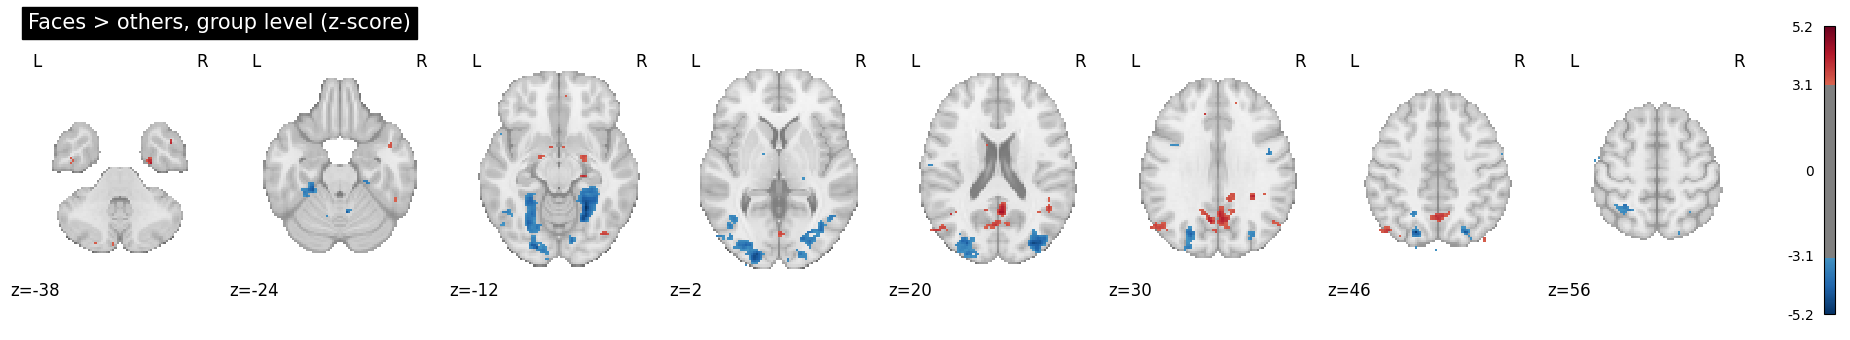

In [ ]:
from nilearn.glm.second_level import SecondLevelModel

# Fitting the group-level GLM in all voxels inside the brain mask
second_level_model = SecondLevelModel(mask_img=mask_file)
second_level_model.fit(subject_maps, design_matrix=design_matrix)

# z-map for the mean faces > others effect across participants
z_map_group = second_level_model.compute_contrast('intercept', output_type='z_score')

# Showing the whole brain as a glass brain, and a row of axial slices
plotting.plot_glass_brain(
    z_map_group,
    threshold=3.1,      # only show voxels with z > 3.1 or z < -3.1 (p < 0.001, uncorrected)
    plot_abs=False,     # show positive and negative values separately
    colorbar=True,
    title='Faces > others, group level (z-score)',
)
plt.show()

plotting.plot_stat_map(
    z_map_group,
    threshold=3.1,
    display_mode='z',   # a row of axial slices
    cut_coords=8,       # number of slices
    title='Faces > others, group level (z-score)',
)
plt.show()

The group-level map shows both positive and negative effects. The largest negative clusters (blue) lie in the medial ventral temporal cortex and the lateral occipital cortex: these regions respond more strongly to the other categories, such as places and objects, than to faces. The positive clusters (red) include the right fusiform gyrus and the right lateral occipital cortex, which contain face-selective regions, but also the precuneus and the angular gyrus. These last two regions are part of the default mode network and are not known for processing faces. Their response is probably less suppressed while participants view faces than while they view the other categories.

The face-selective cluster in the right fusiform gyrus is much smaller than the face-selective spots in many of the individual maps. This is the variability between participants that you saw above: when the FFA lies in a slightly different place in each brain, the effects only partly overlap in MNI space, and the mean effect in each voxel becomes weaker.

<div class='alert alert-info'>
    <b>Reflection:</b>
    <ol>
        <li>In a group-level analysis, what does a large z-value in a voxel tell you? Does it mean that every participant shows the effect in this voxel?</li>
        <li>Suppose we scanned 50 participants instead of 12, and the mean effect and the differences between participants stayed the same. What would happen to the group-level z-values, and why?</li>
        <li>We used a threshold of z > 3.1 (p < 0.001) in roughly 230,000 voxels. How many voxels would you expect to pass this threshold by chance alone, even if there were no true effect anywhere in the brain?</li>
    </ol>
</div>

<details>
<summary><b>Solution</b> (click to expand)</summary>

1. **A large z-value means that the mean effect is large compared with its variability across participants.** It tells us that the effect is likely to be present in the population on average. It does not mean that every participant shows the effect: a few participants may show no effect, or even the opposite effect, as long as the mean is clearly above zero.
2. **They would become larger.** The standard error of the mean effect is the standard deviation across participants divided by the square root of the number of participants. With more participants, the standard error becomes smaller, so the same mean effect gives a larger z-value. With only 12 participants, differences between them, such as the location of the FFA, have a large influence on the standard error. This is one reason why small group studies often miss real effects.
3. **About 230.** At p < 0.001, we expect 1 in 1,000 voxels to pass the threshold by chance: 0.001 × 230,000 ≈ 230 voxels. Some of the smaller clusters in the map are likely to be false positives. In Part III, you will learn how to correct for this.

</details>

**Brief recap**: In this section, you learned that:
- In the **summary statistics approach**, we first fit a GLM to each participant and then combine their contrast estimates in a **group-level GLM**
- A **random-effects analysis** treats participants as a sample from a population, so that the results generalise beyond the people we scanned
- In the group-level design matrix, each row is a participant. A single column of ones tests whether the mean effect differs from zero, which is a **one-sample t-test** in every voxel
- Differences between participants, for example in the location of a region such as the FFA, weaken the effect at the group level

#### Mixed-Effects Analysis

In traditional statistics, we would include participant as a random effect and fit one model to the data of all participants at once. As discussed above, this is not practical for fMRI. The summary statistics approach solves this, but the random-effects analysis we just ran used only one number per participant and voxel: the contrast estimate. It ignored how *precise* each estimate is.

The first-level GLM gives us both pieces of information. For each participant, we get a **contrast map** with the estimated effect in each voxel, and a **variance map** with the uncertainty of that estimate. A participant who moved a lot, or whose data are noisier for other reasons, has a larger variance. A **mixed-effects analysis** uses the variance maps as well: participants with more precise estimates get more weight in the group-level model. This way, the model takes both sources of variability into account: the uncertainty within each participant and the differences between participants.

The variance maps for our 12 participants are stored next to the contrast maps that we used above. We computed both with the same first-level analysis in FSL, with the following settings:
- the six motion parameters (translations and rotations along x, y and z) as nuisance regressors
- a high-pass filter with a cut-off of 100 s (0.01 Hz)
- spatial smoothing with a 4 mm FWHM kernel
- prewhitening to account for temporal autocorrelation

The code below downloads the variance maps and shows them on the same slice as the contrast maps above.

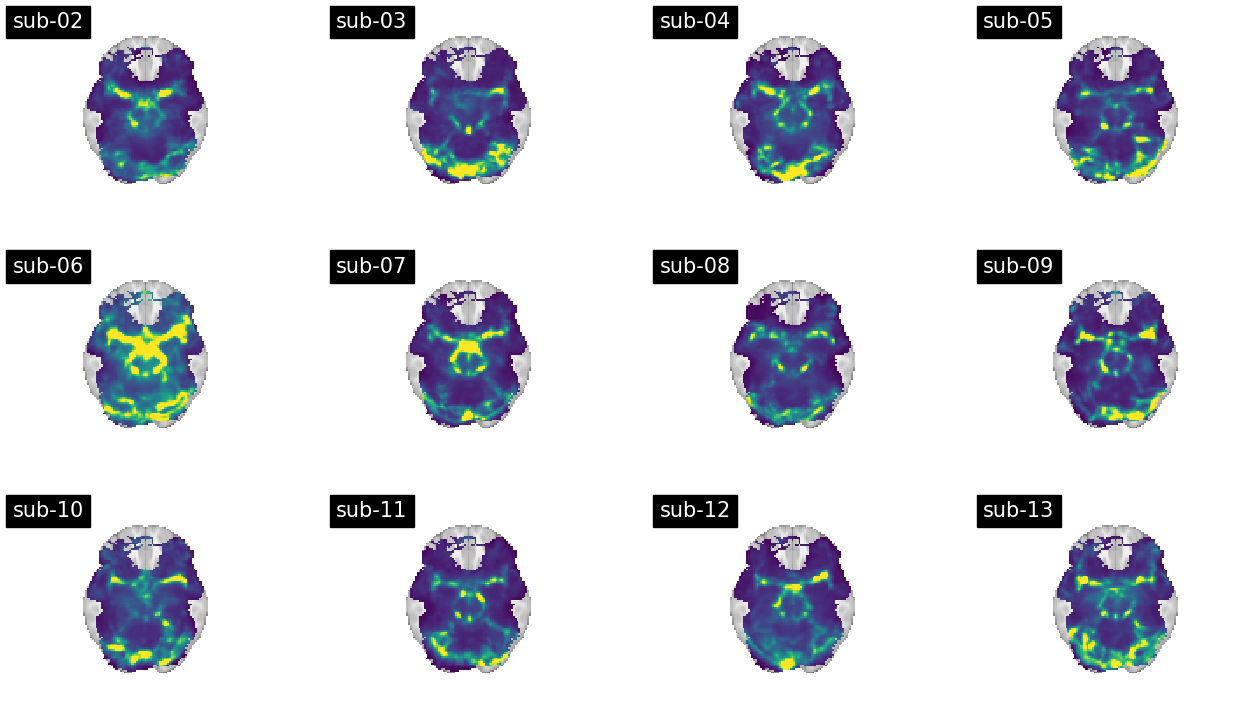

sub-02: 3800
sub-03: 3533
sub-04: 4040
sub-05: 3556
sub-06: 8547
sub-07: 3438
sub-08: 4790
sub-09: 3442
sub-10: 4724
sub-11: 3187
sub-12: 3313
sub-13: 4560


In [ ]:
# 4D image with one variance map per participant, for the same faces > others contrast
var_file = download_openneuro("ds003965", "1.0.0", f"{group_dir}/var_filtered_func_data.nii.gz",
                              "faces_gt_others_variances.nii.gz")

# Contrast maps (from above) and variance maps: one 3D image per participant
beta_imgs = subject_maps
var_imgs = list(image.iter_img(var_file))

# Using the same colour scale for all participants
var_data = image.load_img(var_file).get_fdata()[mask]
vmax_var = np.percentile(var_data, 99)

fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(16, 9))
for ax, var_img, label in zip(axes.flat, var_imgs, subject_labels):
    plotting.plot_stat_map(
        var_img,
        display_mode='z',
        cut_coords=[-18],   # same axial slice as the contrast maps above
        cmap='viridis',
        vmin=0,
        vmax=vmax_var,
        colorbar=False,
        annotate=False,
        title=label,
        axes=ax,
    )
plt.show()

# Median variance inside the brain mask for each participant
for label, median_var in zip(subject_labels, np.median(var_data, axis=0)):
    print(f'{label}: {median_var:.0f}')

The variance maps differ between participants, both in their overall level and in where the variance is high. Most participants have a median variance of around 3,000 to 5,000, but sub-06 has a median variance of about 8,500: the estimates of this participant are much less precise than those of the others.

We now include both the contrast maps and the variance maps in the group-level model. Each participant gets a **weight** of one divided by their variance in that voxel, so that precise estimates count more than noisy ones. In statistics, this is called **weighted least squares** (WLS). nilearn's `SecondLevelModel` does not support weights, so we fit the model ourselves with the `statsmodels` package, one voxel at a time. The design matrix is the same as before: a single column of ones. This takes a few seconds to run.

In [ ]:
import statsmodels.api as sm
from nilearn import masking

# Contrast and variance values inside the brain mask: one row per participant, one column per voxel
betas = masking.apply_mask(beta_imgs, mask_file)
vars_ = masking.apply_mask(var_imgs, mask_file)

# Keeping only voxels with data in all participants (a variance of 0 means no data)
valid = (vars_ > 0).all(axis=0)
betas = betas[:, valid]
vars_ = vars_[:, valid]
n_subjects, n_voxels = betas.shape
print(f'{n_voxels} voxels with data in all {n_subjects} participants')

# Group-level design matrix: a single column of ones, as before
X = np.ones((n_subjects, 1))

group_effects = np.zeros(n_voxels)
group_variances = np.zeros(n_voxels)

for v in range(n_voxels):
    # Each participant is weighted by the inverse of their variance in this voxel
    model = sm.WLS(betas[:, v], X, weights=1 / vars_[:, v])
    result = model.fit()

    group_effects[v] = result.params[0]         # weighted mean across participants
    group_variances[v] = result.bse[0] ** 2     # variance of the weighted mean

# t-value for the weighted mean in each voxel
t_stats = group_effects / np.sqrt(group_variances)

227663 voxels with data in all 12 participants


To compare the weighted model with the unweighted model from Part II, we put the t-values back into a brain image. We also compute the t-map of the unweighted model, and show both maps with the same threshold. With 12 participants, a t-value of 4.02 corresponds to p < 0.001 (uncorrected).

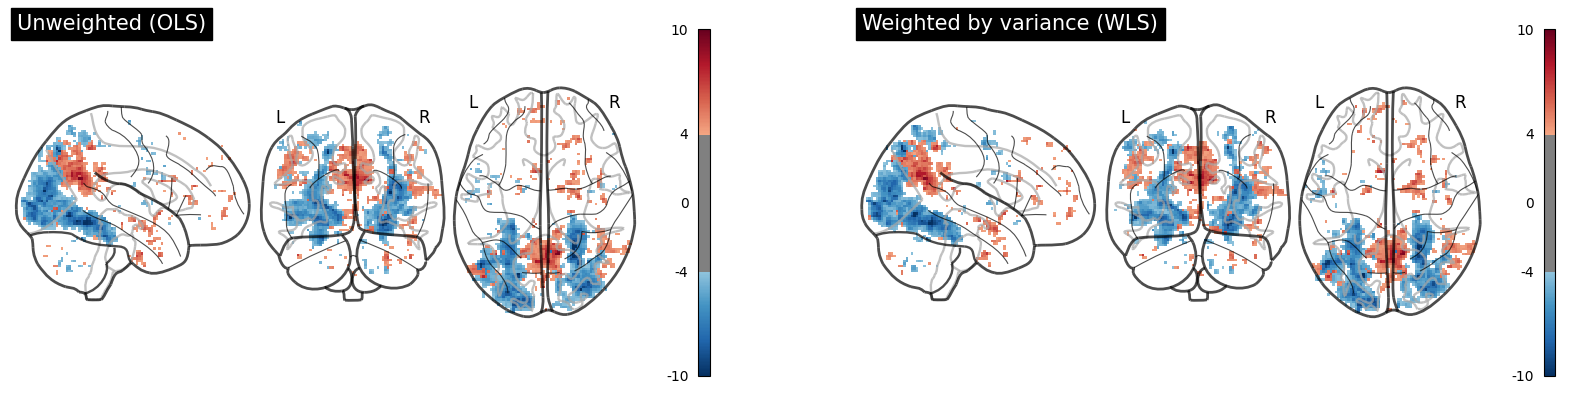

sub-02: 8.2% of the weight (equal weights: 8.3%)
sub-03: 8.9% of the weight (equal weights: 8.3%)
sub-04: 7.7% of the weight (equal weights: 8.3%)
sub-05: 9.2% of the weight (equal weights: 8.3%)
sub-06: 3.7% of the weight (equal weights: 8.3%)
sub-07: 8.8% of the weight (equal weights: 8.3%)
sub-08: 7.0% of the weight (equal weights: 8.3%)
sub-09: 9.5% of the weight (equal weights: 8.3%)
sub-10: 6.9% of the weight (equal weights: 8.3%)
sub-11: 9.7% of the weight (equal weights: 8.3%)
sub-12: 9.6% of the weight (equal weights: 8.3%)
sub-13: 7.2% of the weight (equal weights: 8.3%)


In [ ]:
# Putting the t-values back into a brain image
valid_mask_img = masking.unmask(valid.astype(float), mask_file)
t_map_weighted = masking.unmask(t_stats, image.math_img('img > 0', img=valid_mask_img))

# t-map of the unweighted model from Part II
t_map_unweighted = second_level_model.compute_contrast('intercept', output_type='stat')

fig, axes = plt.subplots(ncols=2, figsize=(20, 5))
for ax, (t_map, title) in zip(axes, [(t_map_unweighted, 'Unweighted (OLS)'),
                                     (t_map_weighted, 'Weighted by variance (WLS)')]):
    plotting.plot_glass_brain(
        t_map,
        threshold=4.02,     # p < 0.001 (uncorrected) with 11 degrees of freedom
        vmax=10,
        plot_abs=False,
        colorbar=True,
        title=title,
        axes=ax,
    )
plt.show()

# How much weight does each participant get, compared with equal weights?
weights = 1 / vars_
weight_share = np.median(weights / weights.sum(axis=0), axis=1)
for label, share in zip(subject_labels, weight_share):
    print(f'{label}: {share:.1%} of the weight (equal weights: {1 / n_subjects:.1%})')

The two maps look very similar: the same clusters appear in both, and slightly more voxels pass the threshold in the weighted model. The weighting mostly changes how much each participant contributes. sub-06, whose estimates are the least precise, gets only about 4% of the weight instead of an equal share of about 8%. With well-behaved data, as here, the weighted and unweighted models usually agree. The weighted model is most useful when a few participants have much noisier data than the rest, for example because they moved a lot.

Note that this is a simplified version of a mixed-effects model. It uses only the variance *within* each participant to set the weights. Full implementations, such as FLAME in FSL, also estimate the variance *between* participants in each voxel and add it to each participant's variance before computing the weights. This makes the weights less extreme when the differences between participants are large.

---
## Part III: Correcting for Multiple Comparisons
---

A group-level analysis tests the same hypothesis in every voxel separately. With roughly 230,000 voxels in our brain mask, we run 230,000 statistical tests. As you saw in the reflection in Part II, a threshold of p < 0.001 would then produce about 230 significant voxels by chance alone, even if no region truly responded. The more tests we run, the more **false positives** we expect.

Methods for **multiple comparison correction** (MCC) adjust the threshold to account for the number of tests. They differ in what they control:
- The **family-wise error rate** (FWER) is the probability of finding *at least one* false positive anywhere in the brain. Bonferroni correction, random field theory and cluster-extent thresholding control the FWER.
- The **false discovery rate** (FDR) is the expected *proportion* of false positives among all significant voxels.

Each method strikes a different balance between finding true effects (**sensitivity**) and avoiding false positives (**specificity**). In this part, we compare the methods on simulated data, where we know the true effect, and then apply them to our group-level map.

*This part is based on a blog post by [Matthew Brett](https://matthew-brett.github.io/teaching/random_fields.html) and an earlier lab by H. Steven Scholte.*

#### A Simulated Example

To see what each method does, we need data in which we know where the true effect is. We therefore simulate a group-level z-map on a simplified 2D "brain" of 200 × 200 voxels. In the middle, we place a round **true effect**, for example a face-selective region. Because fMRI data are spatially smooth, we smooth this effect with a Gaussian kernel of 12 voxels FWHM. We then add random noise that is smoothed with the same kernel.

You do not need to understand every line of the simulation. The code also defines two helper functions that we use throughout this part: `plot_sim_brain` shows a 2D map with a black outline around the true effect, and `count_positives` counts how many significant voxels lie inside the true effect (true positives) and outside it (false positives).

In [ ]:
from scipy import stats
from scipy.ndimage import gaussian_filter

# A round true effect with a z-value of 5.5 in the middle of a 200 x 200 "brain"
k = 200
y, x = np.ogrid[-k // 2:k // 2, -k // 2:k // 2]
signal = np.zeros((k, k))
signal[x**2 + y**2 <= 10**2] = 5.5

# Smoothing the effect with a Gaussian kernel of 12 voxels FWHM
fwhm = 12
sigma = fwhm / np.sqrt(8 * np.log(2))  # converting FWHM to the standard deviation of the kernel
signal_smooth = gaussian_filter(signal, sigma=sigma)

# Smooth random noise with a standard deviation of 1
np.random.seed(10)
noise = gaussian_filter(np.random.normal(0, 1, size=(k, k)), sigma=sigma)
noise = noise / noise.std()

# The simulated z-map: true effect plus noise
sim_data = signal_smooth + noise

# Region in which the true effect is clearly above zero, used to count true and false positives
true_effect = signal_smooth > 0.5

def plot_sim_brain(brain, truth, mask=None, title='', ax=None):
    """Plot a simulated 2D z-map. Voxels outside the mask (if given) are set to 0.
    The black outline shows where the true effect is."""
    if mask is not None:
        brain = np.where(mask, brain, 0)
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 6))
    img = ax.imshow(brain, vmin=-6, vmax=6, cmap='bwr')
    ax.contour(truth.astype(float), levels=[0.5], colors='black', linewidths=1)
    ax.set_title(title)
    ax.axis('off')
    plt.colorbar(img, ax=ax, label='z-value', shrink=0.7)

def count_positives(mask, truth):
    """Print how many significant voxels lie inside (true positives) and outside (false positives) the true effect."""
    n_true = int((mask & truth).sum())
    n_false = int((mask & ~truth).sum())
    print(f'{n_true + n_false} significant voxels: {n_true} true positives, {n_false} false positives')

# Showing the true effect, the noise and the simulated data side by side
fig, axes = plt.subplots(ncols=3, figsize=(18, 5))
for ax, (brain, title) in zip(axes, [(signal_smooth, 'True effect'), (noise, 'Noise'), (sim_data, 'Simulated data')]):
    plot_sim_brain(brain, true_effect, title=title, ax=ax)
plt.show()

#### Uncorrected Thresholds

In the early days of fMRI, researchers simply converted each z-value to a p-value and used a fixed threshold, such as p < 0.05, in every voxel. Let's see what happens if we do the same. The code below converts the z-values of our simulated map to (one-sided) p-values.

In [ ]:
# Significance level
alpha = 0.05

# Converting the z-values to one-sided p-values
sim_pvals = stats.norm.sf(sim_data)

<div class='alert alert-warning'>
<b>ToDo</b>: Count how many voxels have a p-value below <code>alpha</code>, without correcting for multiple comparisons. Store this number in a variable called <code>nsig_uncorrected</code>.
</div>

In [ ]:
# YOUR CODE HERE

The code below shows the uncorrected result. Only the voxels with p < 0.05 are coloured, and the black outline shows where the true effect is.

In [ ]:
uncorrected_mask = sim_pvals < alpha

plot_sim_brain(sim_data, true_effect, mask=uncorrected_mask, title='Uncorrected (p < 0.05)')
plt.show()
count_positives(uncorrected_mask, true_effect)

<div class='alert alert-info'>
    <b>Reflection:</b> Change <code>alpha</code> in the code above to 0.01, then to 0.001, and run the cells again. Does the result look "better"? If you could freely try different thresholds and pick the one with the nicest result, what problem would this create?
</div>

<details>
<summary><b>Solution</b> (click to expand)</summary>

A lower threshold removes many of the false positives, but also part of the true effect. Choosing the threshold *after* looking at the results is a form of circular analysis: the threshold is picked because it makes the results look good in this particular dataset, including its noise. The p-values then no longer mean what they claim to mean, and the number of false positives is inflated. The threshold, and the correction method, must therefore be chosen before looking at the results.

</details>

#### Bonferroni Correction

The uncorrected map contains many false positives. The simplest way to correct for this is the **Bonferroni correction**: we divide the significance level by the number of tests. With 40,000 voxels and α = 0.05, a voxel is only significant if its p-value is below 0.05 / 40,000 = 0.00000125. This keeps the family-wise error rate at 5%.

<div class='alert alert-warning'>
<b>ToDo</b>: Compute the Bonferroni-corrected significance level and store it in a variable called <code>bonf_alpha</code>. Then create a mask of the voxels with a p-value below <code>bonf_alpha</code>, store it in <code>bonf_mask</code>, and plot the result with <code>plot_sim_brain</code>. Use <code>count_positives</code> to count the true and false positives.
</div>

In [ ]:
# YOUR CODE HERE

<div class='alert alert-info'>
    <b>Reflection:</b> With Bonferroni correction, the false positives disappear, but so does most of the true effect. Bonferroni correction is known to be too strict for fMRI data. It assumes that all tests are independent of each other. Why does this assumption not hold for fMRI data?
</div>

<details>
<summary><b>Solution</b> (click to expand)</summary>

fMRI data are spatially smooth: neighbouring voxels have similar values, partly because of the haemodynamic response and the scanner, and partly because we smooth the data during preprocessing. A test in one voxel therefore gives almost the same result as the test in the voxel next to it. The number of truly independent tests is much smaller than the number of voxels, so dividing α by the number of voxels corrects for far more tests than we actually run. The result is a threshold that is stricter than necessary, and many true effects are missed (false negatives).

</details>

#### False Discovery Rate

Bonferroni correction controls the probability of finding even a single false positive. The **false discovery rate** (FDR) takes a different approach: it allows some false positives, but limits their proportion among the significant voxels. With an FDR of 5% (often written as q < 0.05), we accept that, on average, 5% of the significant voxels are false positives.

In [ ]:
from statsmodels.stats.multitest import fdrcorrection

# fdrcorrection expects a 1D array of p-values, so we flatten the map and reshape the result
fdr_mask = fdrcorrection(sim_pvals.ravel(), alpha=0.05)[0].reshape(sim_pvals.shape)

plot_sim_brain(sim_data, true_effect, mask=fdr_mask, title='FDR (q < 0.05)')
plt.show()
count_positives(fdr_mask, true_effect)

FDR correction recovers much more of the true effect than Bonferroni correction. In return, a few of the significant voxels are false positives, roughly the 5% that we accepted.

#### Random Field Theory

As you saw in the reflection on Bonferroni correction, the problem is that neighbouring voxels are not independent. **Random field theory** (RFT) takes the smoothness of the data into account. It estimates how many independent "resolution elements", or **resels**, the data contain. In our 2D simulation, a resel is a square of FWHM × FWHM voxels, so the number of resels is the number of voxels divided by FWHM². In real data, the smoothness has to be estimated from the residuals of the model.

Based on the number of resels, RFT predicts how many blobs we would expect to find above a given z-threshold in pure noise. We then choose the threshold at which we expect fewer than 0.05 blobs: the probability of finding any false positive blob is then about 5%. This controls the family-wise error rate, just like Bonferroni correction, but with far fewer "tests". You do not need to understand the formula in the code below.

In [ ]:
# Number of resels: how many squares of FWHM x FWHM voxels fit in our 2D brain
n_resel = sim_data.size / fwhm**2
print(f'{sim_data.size} voxels, but only about {n_resel:.0f} resels')

def expected_n_blobs(z, n_resel):
    """Expected number of blobs above threshold z in smooth 2D noise, according to random field theory."""
    return n_resel * 4 * np.log(2) * (2 * np.pi) ** -1.5 * z * np.exp(-z**2 / 2)

# Lowest z-threshold at which we expect fewer than 0.05 blobs in pure noise
z_values = np.linspace(2, 6, 1000)
rft_z = z_values[np.argmax(expected_n_blobs(z_values, n_resel) < alpha)]
bonf_z = stats.norm.isf(alpha / sim_data.size)
print(f'RFT threshold: z > {rft_z:.2f} (Bonferroni: z > {bonf_z:.2f})')

rft_mask = sim_data > rft_z
plot_sim_brain(sim_data, true_effect, mask=rft_mask, title=f'RFT (z > {rft_z:.2f})')
plt.show()
count_positives(rft_mask, true_effect)

The RFT threshold is lower than the Bonferroni threshold, so more of the true effect survives, while there are still no false positives. RFT is still fairly strict, however: most of the true effect is missed.

#### Cluster-Extent Thresholding

The methods so far make a decision for each voxel separately, based on its z-value. **Cluster-extent thresholding** instead looks at the *size* of clusters. It works in two steps:
1. Threshold the map at a fixed z-value, for example z > 3.1 (p < 0.001). This gives a number of clusters of neighbouring voxels.
2. Keep only the clusters that are larger than we would expect by chance.

How large can a cluster become by chance? In pure noise with the same smoothness, the largest cluster differs from one map to the next. The code below simulates 1,000 maps of pure noise and records the size of the largest cluster in each. We then use the 95th percentile of these sizes as the minimum cluster size: in only 5% of noise maps would any cluster be this large, so this controls the family-wise error rate. FSL and SPM estimate the same distribution with random field theory instead of simulation.

In [ ]:
from scipy.ndimage import label

def cluster_threshold(z_map, z_thresh, min_size):
    """Keep only clusters of voxels above z_thresh that contain more than min_size voxels."""
    clusters, n_clusters = label(z_map > z_thresh)
    sizes = np.bincount(clusters.ravel())
    keep = [i for i in range(1, n_clusters + 1) if sizes[i] > min_size]
    return np.isin(clusters, keep)

# Size of the largest cluster above z = 3.1 in 1,000 maps of pure noise with the same smoothness
z_thresh = 3.1
np.random.seed(0)
max_cluster_sizes = np.zeros(1000)
for i in range(1000):
    noise_only = gaussian_filter(np.random.normal(0, 1, size=(k, k)), sigma=sigma)
    noise_only = noise_only / noise_only.std()
    clusters, n_clusters = label(noise_only > z_thresh)
    if n_clusters > 0:
        max_cluster_sizes[i] = np.bincount(clusters.ravel())[1:].max()

# Minimum cluster size: the 95th percentile of the largest cluster sizes in pure noise
cluster_size_threshold = np.percentile(max_cluster_sizes, 95)

plt.figure(figsize=(8, 4))
plt.hist(max_cluster_sizes, bins=50, color='skyblue')
plt.axvline(cluster_size_threshold, color='red', linestyle='--', label='95th percentile')
plt.xlabel('Size of the largest cluster (voxels)')
plt.ylabel('Number of noise maps')
plt.legend()
plt.show()
print(f'Minimum cluster size: {cluster_size_threshold:.0f} voxels')

cluster_mask = cluster_threshold(sim_data, z_thresh, cluster_size_threshold)
plot_sim_brain(sim_data, true_effect, mask=cluster_mask, title='Cluster-extent thresholding')
plt.show()
count_positives(cluster_mask, true_effect)

Cluster-extent thresholding recovers a large part of the true effect, without false positives. This is why it is the most widely used correction method in fMRI research. Keep in mind what a significant cluster tells you, though: that there is an effect *somewhere* in the cluster. It does not tell you that every voxel in the cluster is active.

<div class='alert alert-warning'>
<b>ToDo</b>: Cluster-extent thresholding worked well in our example. But what if the true effect is small? The code below simulates new data with a small but strong effect of only 29 voxels, for example a small nucleus. Apply cluster-extent thresholding to <code>sim_data_small</code> (with <code>z_thresh</code> and <code>cluster_size_threshold</code> from above), and store the result in <code>cluster_mask_small</code>. Then apply Bonferroni correction and store the result in <code>bonf_mask_small</code>. Plot both results with <code>plot_sim_brain</code> and count the true and false positives with <code>count_positives</code>.
</div>

In [ ]:
# Please leave this unchanged
small_effect = np.zeros((k, k))
small_effect[x**2 + y**2 <= 3**2] = 7    # a strong effect in a small region of 29 voxels
true_effect_small = small_effect > 0

np.random.seed(5)
noise_small = gaussian_filter(np.random.normal(0, 1, size=(k, k)), sigma=sigma)
noise_small = noise_small / noise_small.std()
sim_data_small = small_effect + noise_small

plot_sim_brain(sim_data_small, true_effect_small, title='Simulated data with a small effect')
plt.show()

# YOUR CODE HERE

<div class='alert alert-info'>
    <b>Reflection:</b> Which of the two methods finds the small effect, and why?
</div>

<details>
<summary><b>Solution</b> (click to expand)</summary>

Bonferroni correction finds the small effect, but cluster-extent thresholding misses it completely. The effect is very strong, so its z-values easily pass the Bonferroni threshold. But the cluster it forms contains only 29 voxels, far fewer than the minimum cluster size of about 90 voxels. Cluster-extent thresholding is only sensitive to effects that are spatially large. Which correction method is best therefore depends on the kind of effect you expect.

</details>

#### Correcting Our Group-Level Map

We now apply the corrections to the group-level z-map from Part II. nilearn's `threshold_stats_img` function computes the threshold for several methods via the `height_control` argument: `'fpr'` for an uncorrected threshold, `'bonferroni'` and `'fdr'`. We use two-sided tests, because we are interested in both positive and negative effects. This is why the uncorrected threshold for p < 0.001 is z > 3.29 here, rather than the z > 3.1 we used before.

In [ ]:
from nilearn.glm import threshold_stats_img

fig, axes = plt.subplots(nrows=3, figsize=(10, 12))
for ax, (height_control, alpha_level, label) in zip(axes, [('fpr', 0.001, 'Uncorrected (p < 0.001)'),
                                                           ('bonferroni', 0.05, 'Bonferroni (p < 0.05)'),
                                                           ('fdr', 0.05, 'FDR (q < 0.05)')]):
    thresholded_map, z_threshold = threshold_stats_img(
        z_map_group,
        mask_img=mask_file,
        alpha=alpha_level,
        height_control=height_control,
        two_sided=True,
    )
    n_voxels = int((thresholded_map.get_fdata() != 0).sum())
    plotting.plot_glass_brain(
        thresholded_map,
        threshold=z_threshold,
        plot_abs=False,
        colorbar=True,
        title=f'{label}: |z| > {z_threshold:.2f}, significant voxels: {n_voxels}',
        axes=ax,
    )
plt.show()

The methods give very different results. With Bonferroni correction, the threshold rises to about |z| > 5.2, and only a single voxel survives. With FDR correction, about 4,600 voxels survive, almost as many as with the uncorrected threshold. This shows an important property of FDR: its threshold adapts to the data. When many voxels show a true effect, as in our faces > others map, the FDR threshold becomes lenient. When only a few voxels show an effect, it becomes almost as strict as Bonferroni correction. Note that, with q < 0.05, we expect about 5% of these 4,600 voxels, or roughly 230, to be false positives.

nilearn does not offer random field theory or cluster-extent thresholding based on the smoothness of the data. In the next part, you will see that permutation tests offer a way to control the family-wise error rate that, like random field theory, takes the smoothness of the data into account.

<div class='alert alert-info'>
    <b>Reflection:</b>
    <ol>
        <li>Based on how Bonferroni correction and random field theory work, name two ways in which you could make a family-wise error correction less strict, so that it finds more of the true effects.</li>
        <li>In the FDR-corrected map, about 4,600 voxels are significant. What can you conclude about a single voxel in this map? How does this differ from a voxel in the Bonferroni-corrected map?</li>
    </ol>
</div>

<details>
<summary><b>Solution</b> (click to expand)</summary>

1. **Reduce the number of tests, or make them less independent.** You can test fewer voxels, for example by restricting the analysis to a region of interest (see Part V). You can also smooth the data more: smoother data contain fewer resels, so random field theory corrects for fewer independent tests. Note that more smoothing also blurs small effects.
2. **FDR makes a statement about the set of voxels, not about each voxel.** With q < 0.05, we expect about 5% of the significant voxels to be false positives, but we do not know which ones. Any single voxel may be one of them. With Bonferroni correction, the probability that *any* of the significant voxels is a false positive is only 5%, so we can be much more confident about each individual voxel.

</details>

**Brief recap**: In this section, you learned that:
- Testing every voxel leads to many **false positives**, so we need to correct for multiple comparisons
- **Bonferroni correction** divides α by the number of tests. It controls the **family-wise error rate** (FWER), but is too strict for fMRI, because neighbouring voxels are not independent
- The **false discovery rate** (FDR) limits the proportion of false positives among the significant voxels. It is more sensitive, and its threshold adapts to the amount of true effect in the data
- **Random field theory** controls the FWER while taking the smoothness of the data into account, by estimating the number of independent resels
- **Cluster-extent thresholding** keeps only clusters that are larger than expected by chance. It is sensitive to large effects, but misses small ones, and only tells you that there is an effect somewhere in the cluster

---
## Part IV: Non-Parametric Analysis
---

So far in this course, we have used **parametric** tests. These tests assume that the data follow a known distribution, usually the normal distribution, and use this distribution to compute p-values. With only 12 participants, it is hard to check whether this assumption holds.

**Non-parametric** tests do not need this assumption. Instead of using a theoretical distribution, they build the null distribution from the data themselves. The data are shuffled many times in a way that removes any true effect, and the test statistic is computed again after each shuffle. The result is an **empirical null distribution**: the values we would expect by chance alone. We then check how extreme the observed value is compared with this distribution.

The main drawback of non-parametric tests is that they need more computation, because the analysis is repeated hundreds or thousands of times. For group-level fMRI analyses, this is usually feasible, and permutation tests are now widely used in neuroimaging. As you will see, they also offer another way to correct for multiple comparisons.

#### Simulation

To build some intuition, we start with **simulated data** for a single voxel, for example a voxel in the right fusiform face area. We simulate the faces > others contrast estimates of 12 participants: the same kind of data that our group-level analysis has in each voxel. The question is also the same as before: is the mean effect across participants different from zero?

How can we shuffle data that consist of a single value per participant? If there were no true effect, each participant's estimate would be equally likely to be positive or negative. We can therefore randomly **flip the sign** of each participant's estimate and get data that are just as likely under the null hypothesis. The permutation test works as follows:
1. Compute the observed mean effect across participants.
2. Randomly flip the sign of each participant's estimate, and compute the mean again.
3. Repeat step 2 many times. The resulting means form the null distribution.
4. The p-value is the proportion of permuted means that are at least as extreme as the observed mean.

In [ ]:
# Simulating the faces > others estimates of 12 participants in one voxel, with a true mean effect of 0.5
np.random.seed(42)
n_subjects = 12
effects = np.random.normal(0.5, 1, n_subjects)

# Observed mean effect across participants
observed_mean = np.mean(effects)

# Building the null distribution by randomly flipping the sign of each participant's estimate
n_permutations = 500
perm_means = np.zeros(n_permutations)
for i in range(n_permutations):
    signs = np.random.choice([-1, 1], size=n_subjects)
    perm_means[i] = np.mean(signs * effects)

# p-value: proportion of permuted means at least as extreme as the observed mean (two-sided)
p_value = np.mean(np.abs(perm_means) >= np.abs(observed_mean))

plt.figure(figsize=(8, 5))
plt.hist(perm_means, bins=30, color='skyblue', label='Null distribution (sign-flipped means)')
plt.axvline(observed_mean, color='red', linestyle='--', label='Observed mean')
plt.xlabel('Mean effect across participants')
plt.ylabel('Number of permutations')
plt.title('Permutation test for one voxel (simulated data)')
plt.legend()
plt.show()

print(f'Permutation p-value: {p_value:.3f}')

The histogram shows the null distribution: the mean effects we would expect if the sign of each participant's estimate were random. The observed mean lies in the far tail of this distribution. Very few permuted means are as extreme, so the p-value is small.

Because the p-value is a proportion of a limited number of permutations, its precision depends on how many permutations we run. With 500 permutations, the smallest p-value above zero is 1/500 = 0.002, and the p-value changes slightly every time you run the test with different random sign flips. More permutations give a more precise p-value, but take longer to compute.

<div class='alert alert-warning'>
<b>ToDo</b>: Simulate the faces > others estimates of 12 participants in one voxel, with a true mean effect of 0.2 and a standard deviation of 1. Then run the sign-flipping permutation test on these data:
<ul>
<li>with 500 permutations: store the p-value in <code>p_500</code></li>
<li>with 1000 permutations: store the p-value in <code>p_1000</code></li>
</ul>
How do the two p-values compare, and why do they differ?
</div>

In [ ]:
# Please leave this unchanged
np.random.seed(42)
n_subjects = 12

# YOUR CODE HERE

#### Permutation Test for the Whole Brain

Now that you know what happens under the hood, we apply the same test to our group-level data with nilearn's `non_parametric_inference`. It randomly flips the signs of the 12 contrast maps, fits the group-level model again, and repeats this 500 times. We use the same design matrix as in Part II.

There is one important difference with the single-voxel simulation. In each permutation, nilearn records the **largest** absolute t-value across the whole brain. The p-value of a voxel is the proportion of permutations in which the largest t-value *anywhere in the brain* was at least as extreme as the t-value in this voxel. This is the same idea as the cluster-size simulation in Part III, but applied to t-values and to the real data. It controls the **family-wise error rate**: if there were no true effect, only 5% of experiments would show any significant voxel at all. Because the null distribution comes from the data themselves, it automatically takes the smoothness of the data into account.

In [ ]:
from nilearn.glm.second_level import non_parametric_inference

# Permutation test with sign flipping. The output is an image of -log10(p), corrected for multiple comparisons
neg_log_pvals_img = non_parametric_inference(
    second_level_input=beta_imgs,         # contrast maps of the 12 participants
    design_matrix=design_matrix,          # same design matrix as in Part II: a single column of ones
    second_level_contrast='intercept',    # mean effect across participants
    model_intercept=False,                # the intercept is already in the design matrix
    mask=mask_file,
    n_perm=500,                           # number of permutations
    two_sided_test=True,                  # test for positive and negative effects
    random_state=0,                       # makes the permutations reproducible
)

# p < 0.05 corresponds to -log10(p) > 1.3
threshold = -np.log10(0.05)

plotting.plot_glass_brain(
    neg_log_pvals_img,
    threshold=threshold,
    colorbar=True,
    cmap='viridis',
    title='Faces > others, permutation test (p < 0.05, corrected)',
)
plt.show()

n_significant = int((neg_log_pvals_img.get_fdata() > threshold).sum())
print(f'{n_significant} voxels with p < 0.05 (corrected)')

Only a handful of voxels survive the correction. All of them have a *negative* effect: they lie in the right medial ventral temporal cortex and the left lateral occipital cortex, where the response to the other categories is stronger than the response to faces. The p-value map does not show the direction of an effect, but you can find it in the z-map from Part II. None of the face-selective regions, such as the right FFA, survive.

This is more than with Bonferroni correction in Part III (a single voxel), because the permutation test takes the smoothness of the data into account. Still, in Part II, about 6,800 voxels passed the uncorrected threshold of p < 0.001. Correcting for multiple comparisons across roughly 230,000 voxels is very strict, especially with only 12 participants. This is one reason why group-level studies need enough participants, and why researchers often reduce the number of tests, for example by analysing a region of interest that was chosen in advance.

**Brief recap**: In this section, you learned that:
- **Non-parametric** tests build the null distribution from the data themselves, instead of assuming a theoretical distribution such as the normal distribution
- For a group-level test of the mean effect, the null distribution is built by randomly **flipping the sign** of each participant's estimate
- The precision of a permutation p-value depends on the number of permutations: with 500 permutations, the smallest p-value above zero is 0.002
- By recording the **largest** t-value across the brain in each permutation, a permutation test controls the **family-wise error rate**: the probability of any false positive in the whole brain

---
## Part V: Region-of-Interest Analysis
---

So far, we have tested every voxel in the brain. As you saw in Parts III and IV, correcting for multiple comparisons across roughly 230,000 voxels is very strict, and only a handful of voxels survived. Often, however, we have a hypothesis about a specific brain region. In our case, we expect faces to activate the **fusiform face area** (FFA) in the right fusiform gyrus.

In a **region-of-interest (ROI) analysis**, we restrict the analysis to this region. The analysis itself stays exactly the same: the same group-level model, the same contrast and the same test in each voxel. The only thing that changes is the **search space**. Because we test far fewer voxels, the correction for multiple comparisons becomes much less strict, and the test becomes more sensitive. Some studies go one step further and average all voxels in the ROI, which leaves a single test per ROI.

The ROI must be chosen **independently of the data** that we test, for example from an anatomical atlas, from a previous study, or from a separate localiser run. We will come back to why this matters in the reflection at the end of this part.

#### Defining the ROI

We use the Harvard-Oxford atlas from Part I to define an anatomical ROI: the **right temporal occipital fusiform cortex**, which contains the FFA. We load the version of the atlas with separate labels for the left and right hemisphere, and resample it to the voxel grid of our data. The code below shows the outline of the ROI on top of the group-level z-map from Part II.

In [ ]:
# Harvard-Oxford atlas with separate labels for the left and right hemisphere
atlas_ho = datasets.fetch_atlas_harvard_oxford('cort-maxprob-thr25-2mm', symmetric_split=True)

# Resampling the atlas to the voxel grid of our data (nearest-neighbour interpolation keeps the labels intact)
atlas_img = image.resample_to_img(atlas_ho.maps, mask_file, interpolation='nearest')

# ROI: the right temporal occipital fusiform cortex, restricted to voxels inside the group brain mask
roi_index = atlas_ho.labels.index('Right Temporal Occipital Fusiform Cortex')
roi_img = image.math_img(f'((atlas == {roi_index}) & (mask > 0)).astype("int8")',
                         atlas=atlas_img, mask=mask_file)
print(f'{int(roi_img.get_fdata().sum())} voxels in the ROI')

# Showing the outline of the ROI on top of the group-level z-map from Part II
roi_display = plotting.plot_stat_map(
    z_map_group,
    threshold=3.1,
    cut_coords=(30, -52, -14),  # slices through the right fusiform gyrus
    title='Group-level z-map with the ROI outline',
)
roi_display.add_contours(roi_img, levels=[0.5], colors='black')
plt.show()

#### Permutation Test Within the ROI

We now run exactly the same permutation test as in Part IV. The only change is the `mask` argument: instead of the whole-brain mask, we pass the ROI.

In [ ]:
# Same permutation test as in Part IV: only the mask has changed
neg_log_pvals_roi_img = non_parametric_inference(
    second_level_input=beta_imgs,
    design_matrix=design_matrix,
    second_level_contrast='intercept',
    model_intercept=False,
    mask=roi_img,                         # the ROI instead of the whole brain
    n_perm=500,
    two_sided_test=True,
    random_state=0,
)

# Number of significant voxels in the whole-brain analysis (Part IV) and in the ROI analysis
for label, img in [('Whole brain', neg_log_pvals_img), ('ROI', neg_log_pvals_roi_img)]:
    n_significant = int((img.get_fdata() > threshold).sum())
    print(f'{label}: {n_significant} voxels with p < 0.05 (corrected)')

roi_display = plotting.plot_stat_map(
    neg_log_pvals_roi_img,
    threshold=threshold,                  # p < 0.05 (corrected), as in Part IV
    cmap='viridis',
    cut_coords=(30, -52, -14),
    title='Permutation test within the ROI (p < 0.05, corrected)',
)
roi_display.add_contours(roi_img, levels=[0.5], colors='black')
plt.show()

Within the ROI, almost 200 voxels survive the correction, compared with only 8 in the whole-brain analysis. The data and the t-value in each voxel are exactly the same as before. What has changed is the null distribution. In each permutation, the test records the largest t-value in the search space. Across the whole brain, this is the largest of about 230,000 t-values, and a voxel needed a t-value of about 9.9 to survive. Within the ROI, it is the largest of about 800 t-values, and the threshold drops to about 4.7.

As in the whole-brain analysis, all surviving voxels have a negative effect. They lie in the medial part of the fusiform gyrus, which responds more strongly to places and objects than to faces. The face-selective voxels on the lateral side of the ROI do not survive. An ROI makes the test more sensitive, but it cannot rescue an effect that is not consistent across participants. As you saw in the individual maps in Part II, the location of the FFA differs between participants, so the faces > others effect in any single voxel of MNI space is weak at the group level.

<div class='alert alert-info'>
    <b>Reflection:</b>
    <ol>
        <li>Suppose we had defined the ROI as the cluster with the strongest effect in the group-level z-map from Part II, and then tested the same data within this ROI. Why would this be a problem?</li>
        <li>What do we lose when we restrict the analysis to an ROI?</li>
    </ol>
</div>

<details>
<summary><b>Solution</b> (click to expand)</summary>

1. **The test would be circular.** A cluster has the strongest effect partly because of a true effect, and partly because the noise happened to push the values up in this sample. If we select the ROI and test it with the same data, this noise is counted twice: once to select the ROI and once to test it. The result is almost guaranteed to be significant, even if there were no true effect. This is known as **double dipping**. An ROI must therefore be defined independently of the data we test, for example from an atlas, a previous study, or a separate localiser run.
2. **We can only draw conclusions about the ROI.** Effects outside the ROI are not tested at all, so we cannot say anything about them. We also cannot claim that an effect is *specific* to the ROI, because we never checked whether other regions show the same effect.

</details>

**Brief recap**: In this section, you learned that:
- A **region-of-interest (ROI) analysis** uses the same model and the same test as a whole-brain analysis. Only the **search space** is reduced to the ROI
- Because fewer voxels are tested, the correction for multiple comparisons is less strict, so the test is more sensitive within the ROI
- An ROI cannot rescue an effect that is not consistent across participants
- The ROI must be defined **independently** of the data we test, for example from an anatomical atlas. Selecting an ROI from the same data and then testing it is circular (**double dipping**)

---
### Up next

This week, we moved from a single participant to a group. We combined the contrast maps of 12 participants in a group-level GLM, weighted participants by the precision of their estimates in a mixed-effects analysis, and corrected for the many tests we run across the brain, with parametric methods, permutation tests and regions of interest.

Throughout these analyses, we treated the stimuli as completely separate categories. The faces > others contrast assumes that bodies, places, characters and objects are all equally different from faces, and that every face is the same as every other face. In reality, stimuli differ from each other in graded ways: a body shares more features with a face than a house does, and two faces can be more or less alike. Next week, we will use this information with **encoding and decoding models**:

- **Similarity between stimuli**: instead of category labels, we will describe each stimulus by its features, and quantify how similar the stimuli are to each other.
- **Encoding models**: we will use these features to predict the response of each voxel. This allows us to describe what a voxel responds to, and to compare voxels by how similar their responses are.
- **Decoding models**: we will reverse the direction, and predict from the pattern of activity across many voxels which stimulus a participant saw.